In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from scipy import stats
from scipy.stats import mannwhitneyu

In [64]:
url_gasto_energetico = "../data/processed/gasto_energetico_hogar2.csv"

df_gasto_energetico = pd.read_csv(url_gasto_energetico)

print(df_gasto_energetico.info())


<class 'pandas.DataFrame'>
RangeIndex: 19544 entries, 0 to 19543
Data columns (total 87 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GASTO_SUMINISTROS  19544 non-null  float64
 1   CCAA               19544 non-null  str    
 2   NUTS1              19544 non-null  str    
 3   CAPROV             19544 non-null  str    
 4   TAMAMU             19544 non-null  str    
 5   DENSIDAD           19544 non-null  str    
 6   NMIEMB             19544 non-null  int64  
 7   NMIEM1             19544 non-null  int64  
 8   NMIEM2             19544 non-null  int64  
 9   NMIEM3             19544 non-null  int64  
 10  NMIEM4             19544 non-null  int64  
 11  NMIEM5             19544 non-null  int64  
 12  NMIEM6             19544 non-null  int64  
 13  NMIEM7             19544 non-null  int64  
 14  NMIEM8             19544 non-null  int64  
 15  NMIEM9             19544 non-null  int64  
 16  NMIEM10            19544 non-null

In [65]:
train_set, test_set = train_test_split(df_gasto_energetico, test_size=0.2, random_state=42)
target = "GASTO_SUMINISTROS"

X_train = train_set.drop(columns=[target]).copy()
y_train = train_set[target].copy()

X_test = test_set.drop(columns=[target]).copy()
y_test = test_set[target].copy()

In [66]:
no_num = train_set.select_dtypes(exclude="number").columns.tolist()

no_num_binary = [
    col for col in no_num
    if train_set[col].nunique(dropna=False) == 2
]

bin_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(
        drop="if_binary",        # deja 1 columna binaria (0.0 / 1.0) por variable
        handle_unknown="ignore", # evita fallos si aparece un valor inesperado en test_set
        sparse_output=False,     # devuelve array denso de numpy en vez de matriz dispersa
    )),
])

X_train_bin = bin_pipeline.fit_transform(train_set[no_num_binary])

cols_bin_out = bin_pipeline.get_feature_names_out(no_num_binary)
df_train_bin = pd.DataFrame(X_train_bin, columns=cols_bin_out, index=train_set.index)

#print(df_train_bin.head().to_string())
train_set_with_bin = train_set.drop(columns=no_num_binary).copy()
train_set_with_bin = pd.concat([train_set_with_bin, df_train_bin], axis=1)
train_set_with_bin.head()

,GASTO_SUMINISTROS,CCAA,NUTS1,TAMAMU,DENSIDAD,NMIEMB,NMIEM1,NMIEM2,NMIEM3,NMIEM4,...,DISPOSIOV_Sí,CAPROP_Si,CAJENA_Si,PENSIOJUB_Si,PENSIOINCAP_Si,PENSIOTR_Si,DESEM_Si,OTRSUB_Si,RENTAS_Si,OTROIN_Si
982,1399.615590,"Rioja, La",Noreste,Municipio con 20.000 o más y menos de 50.000 h...,Zona intermedia,2,2,0,0,2,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
11622,1969.438353,País Vasco,Noreste,Municipio con 10.000 o más y menos de 20.000 h...,Zona intermedia,1,1,0,0,1,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14403,398.795238,Comunitat Valenciana,Este,Municipio con 20.000 o más y menos de 50.000 h...,Zona densamente poblada,1,1,0,0,1,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
11208,1294.424373,Cantabria,Noroeste,Municipio con menos de 10.000 habitantes,Zona intermedia,3,3,0,0,3,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19219,1250.601399,Comunitat Valenciana,Este,Municipio con 50.000 o más y menos 100.000 hab...,Zona intermedia,4,2,2,2,2,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


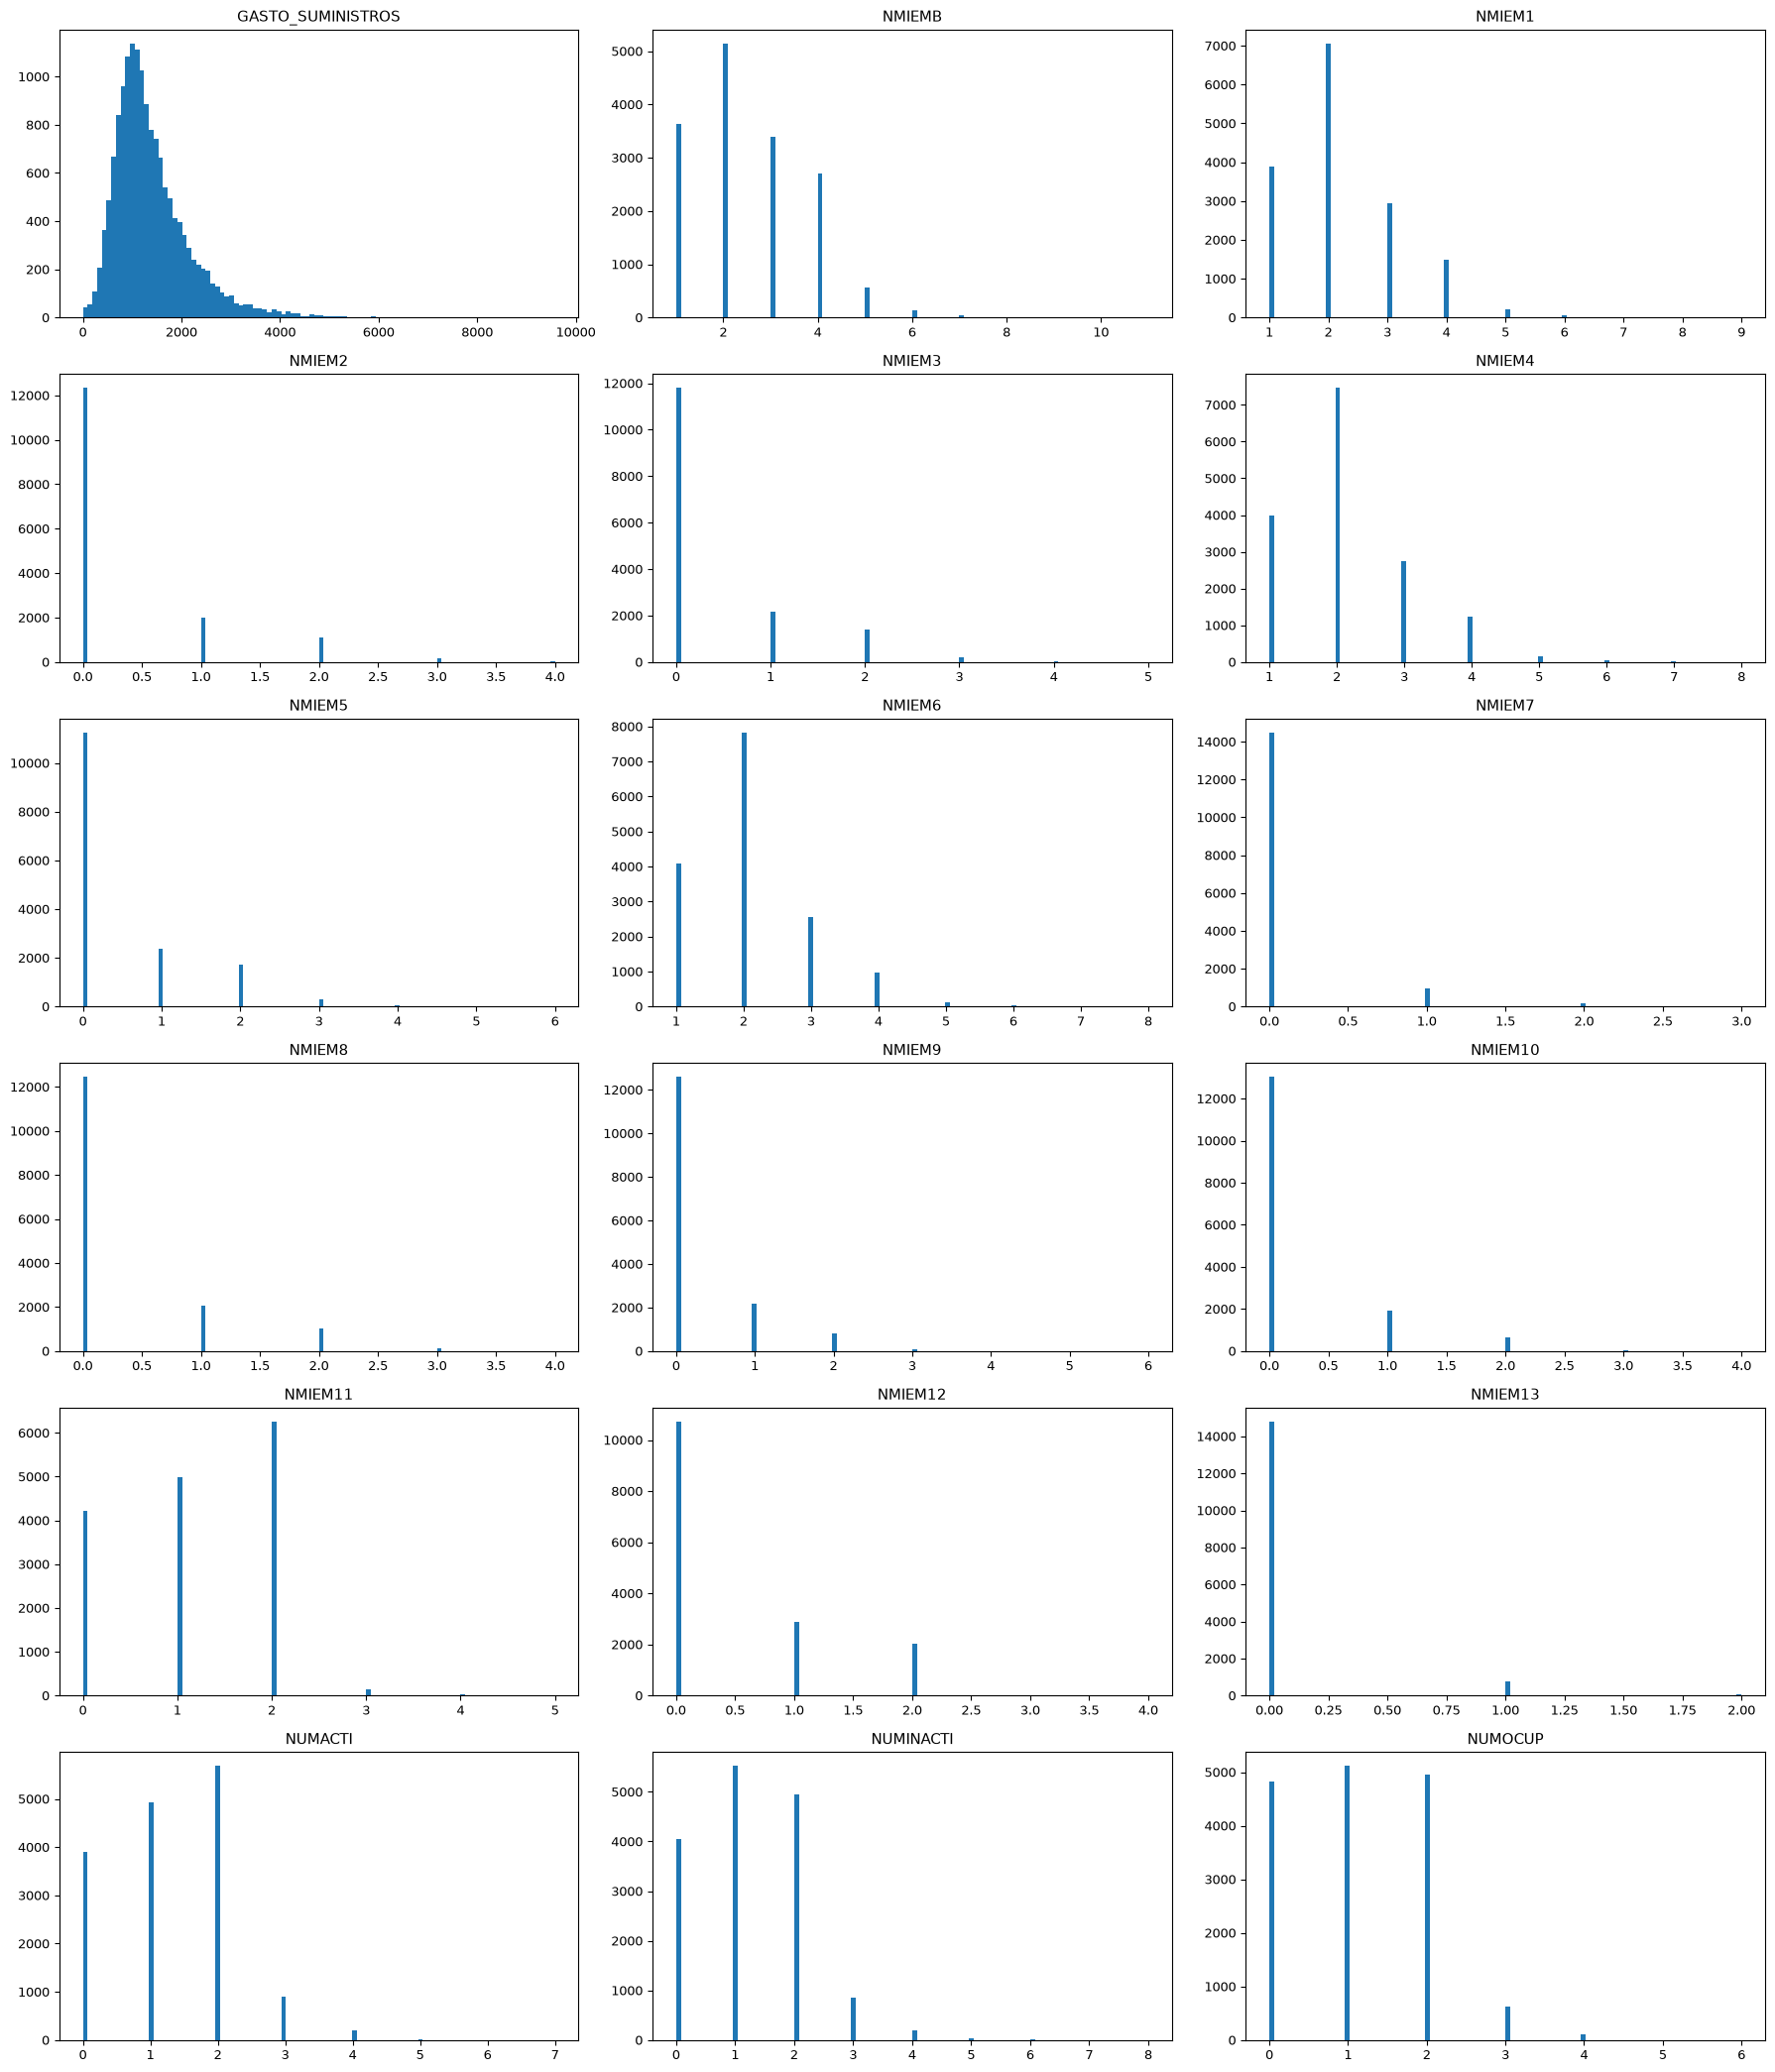

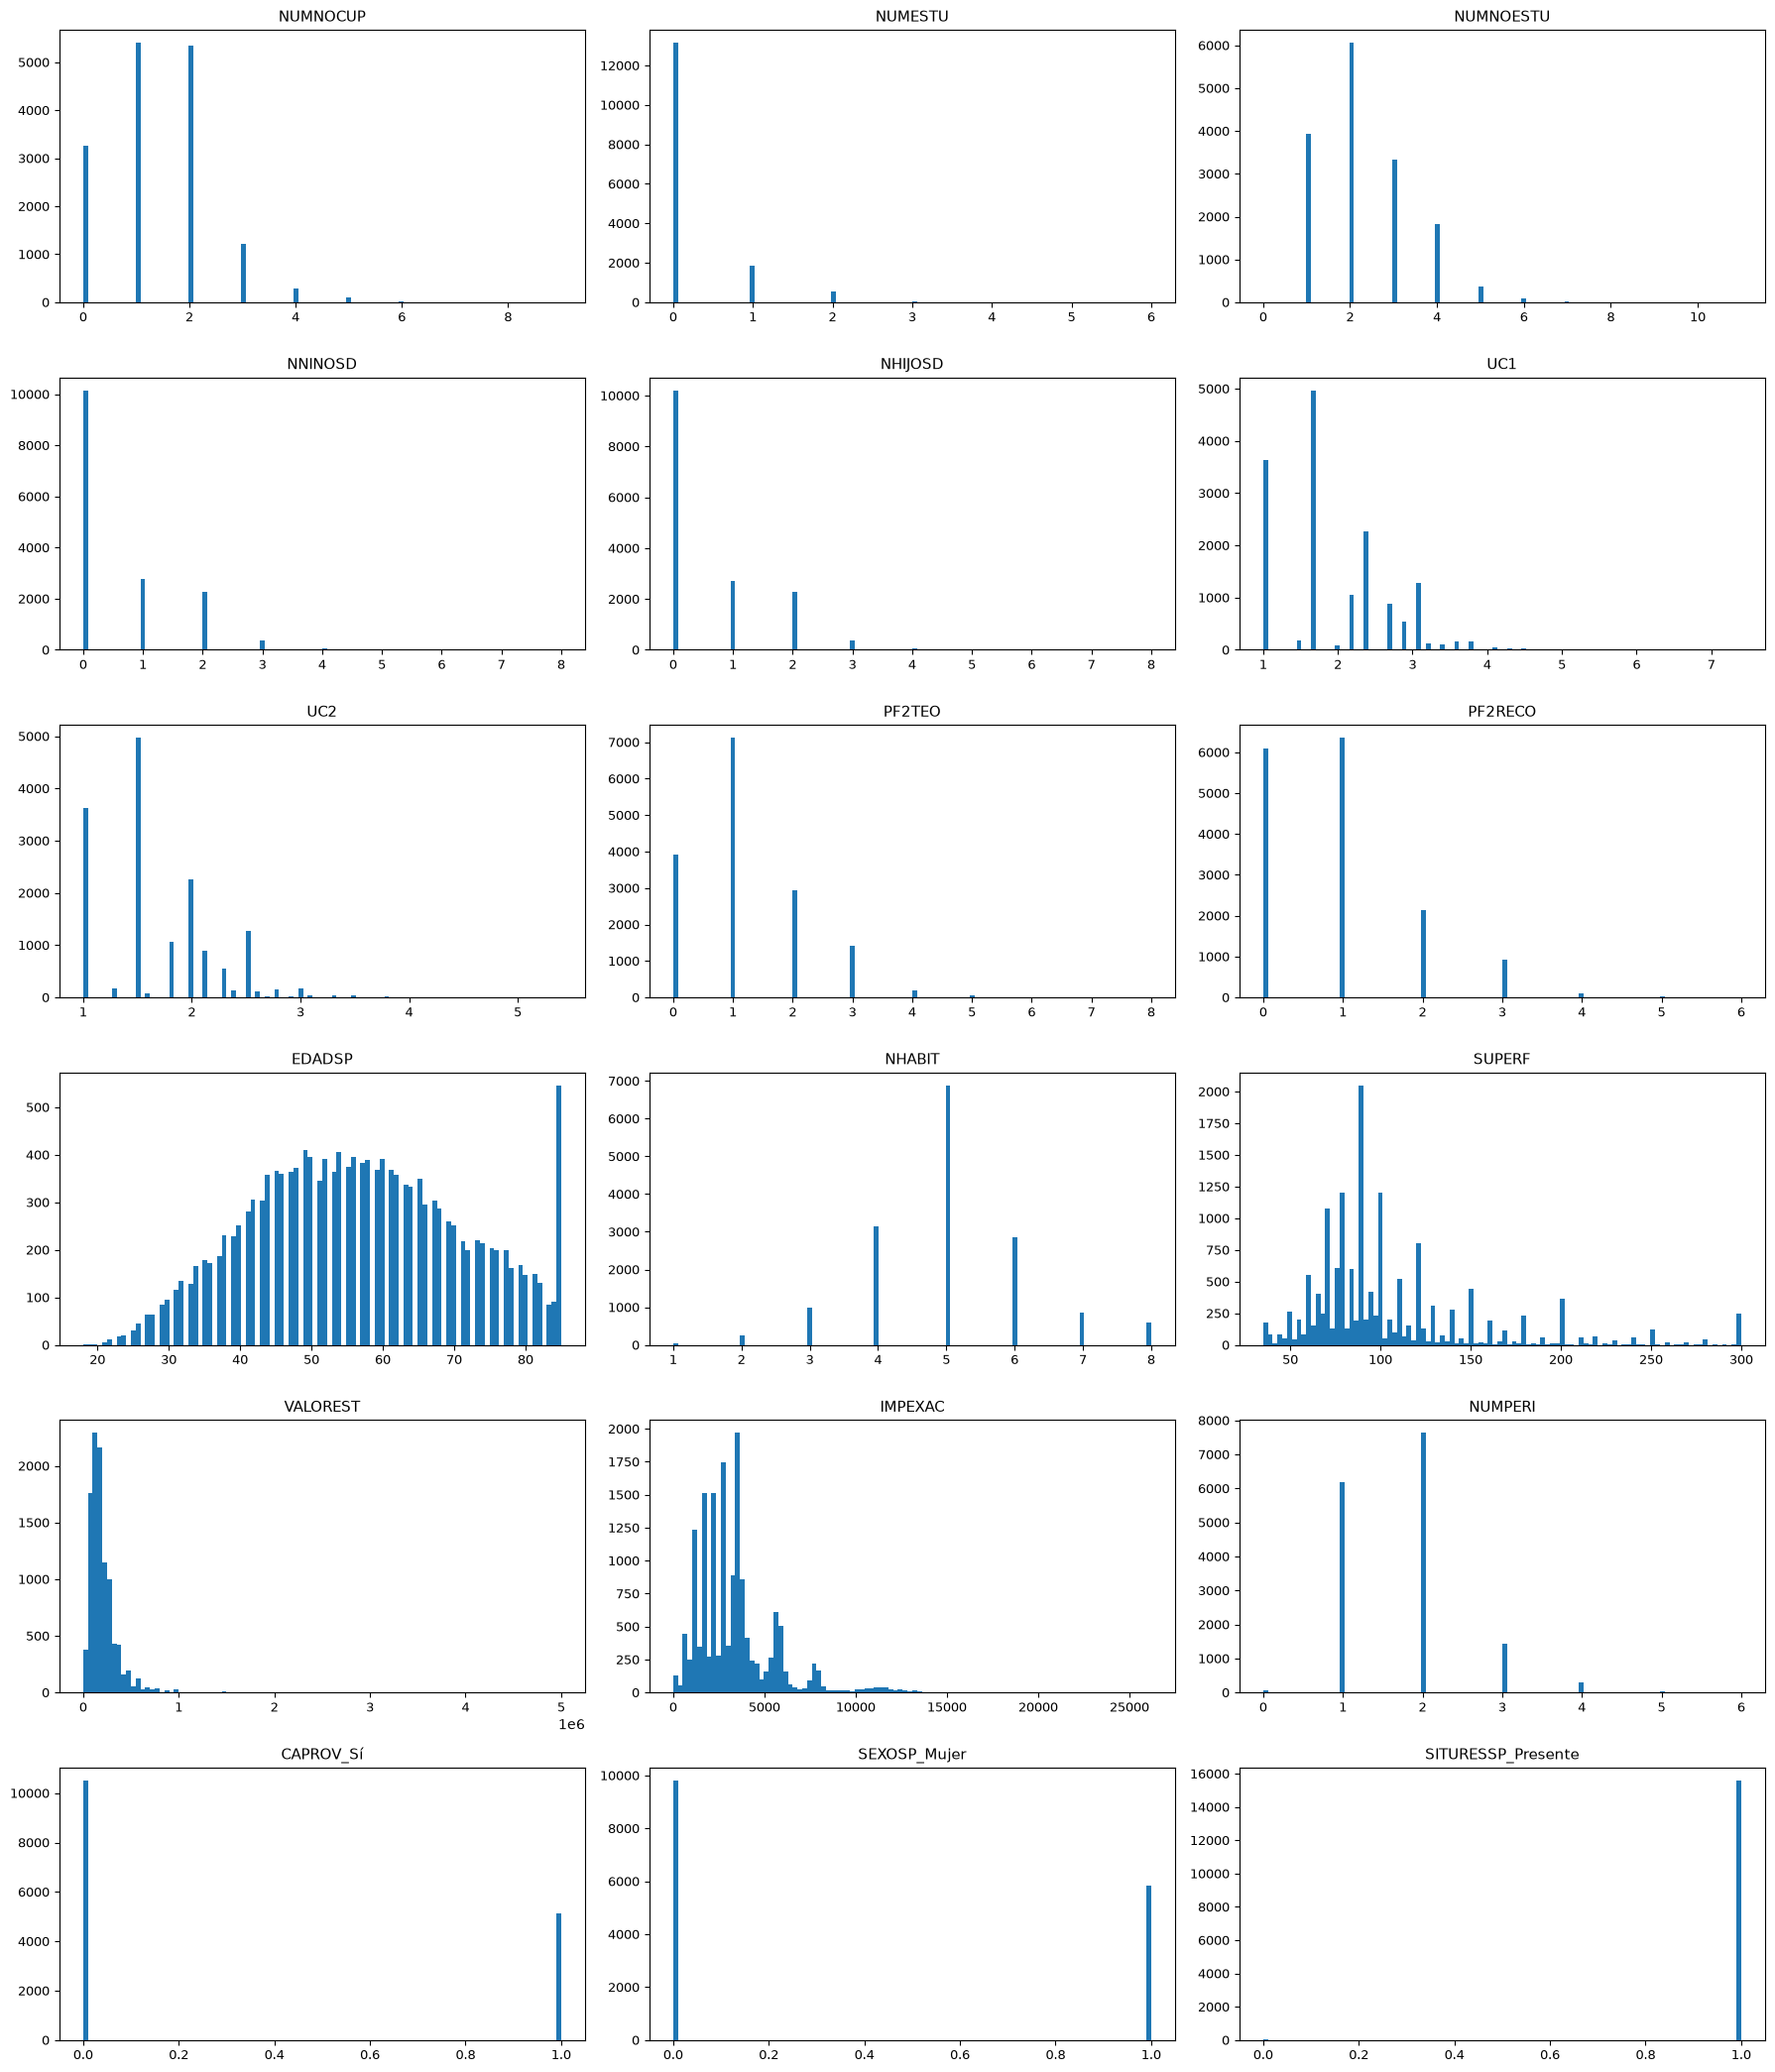

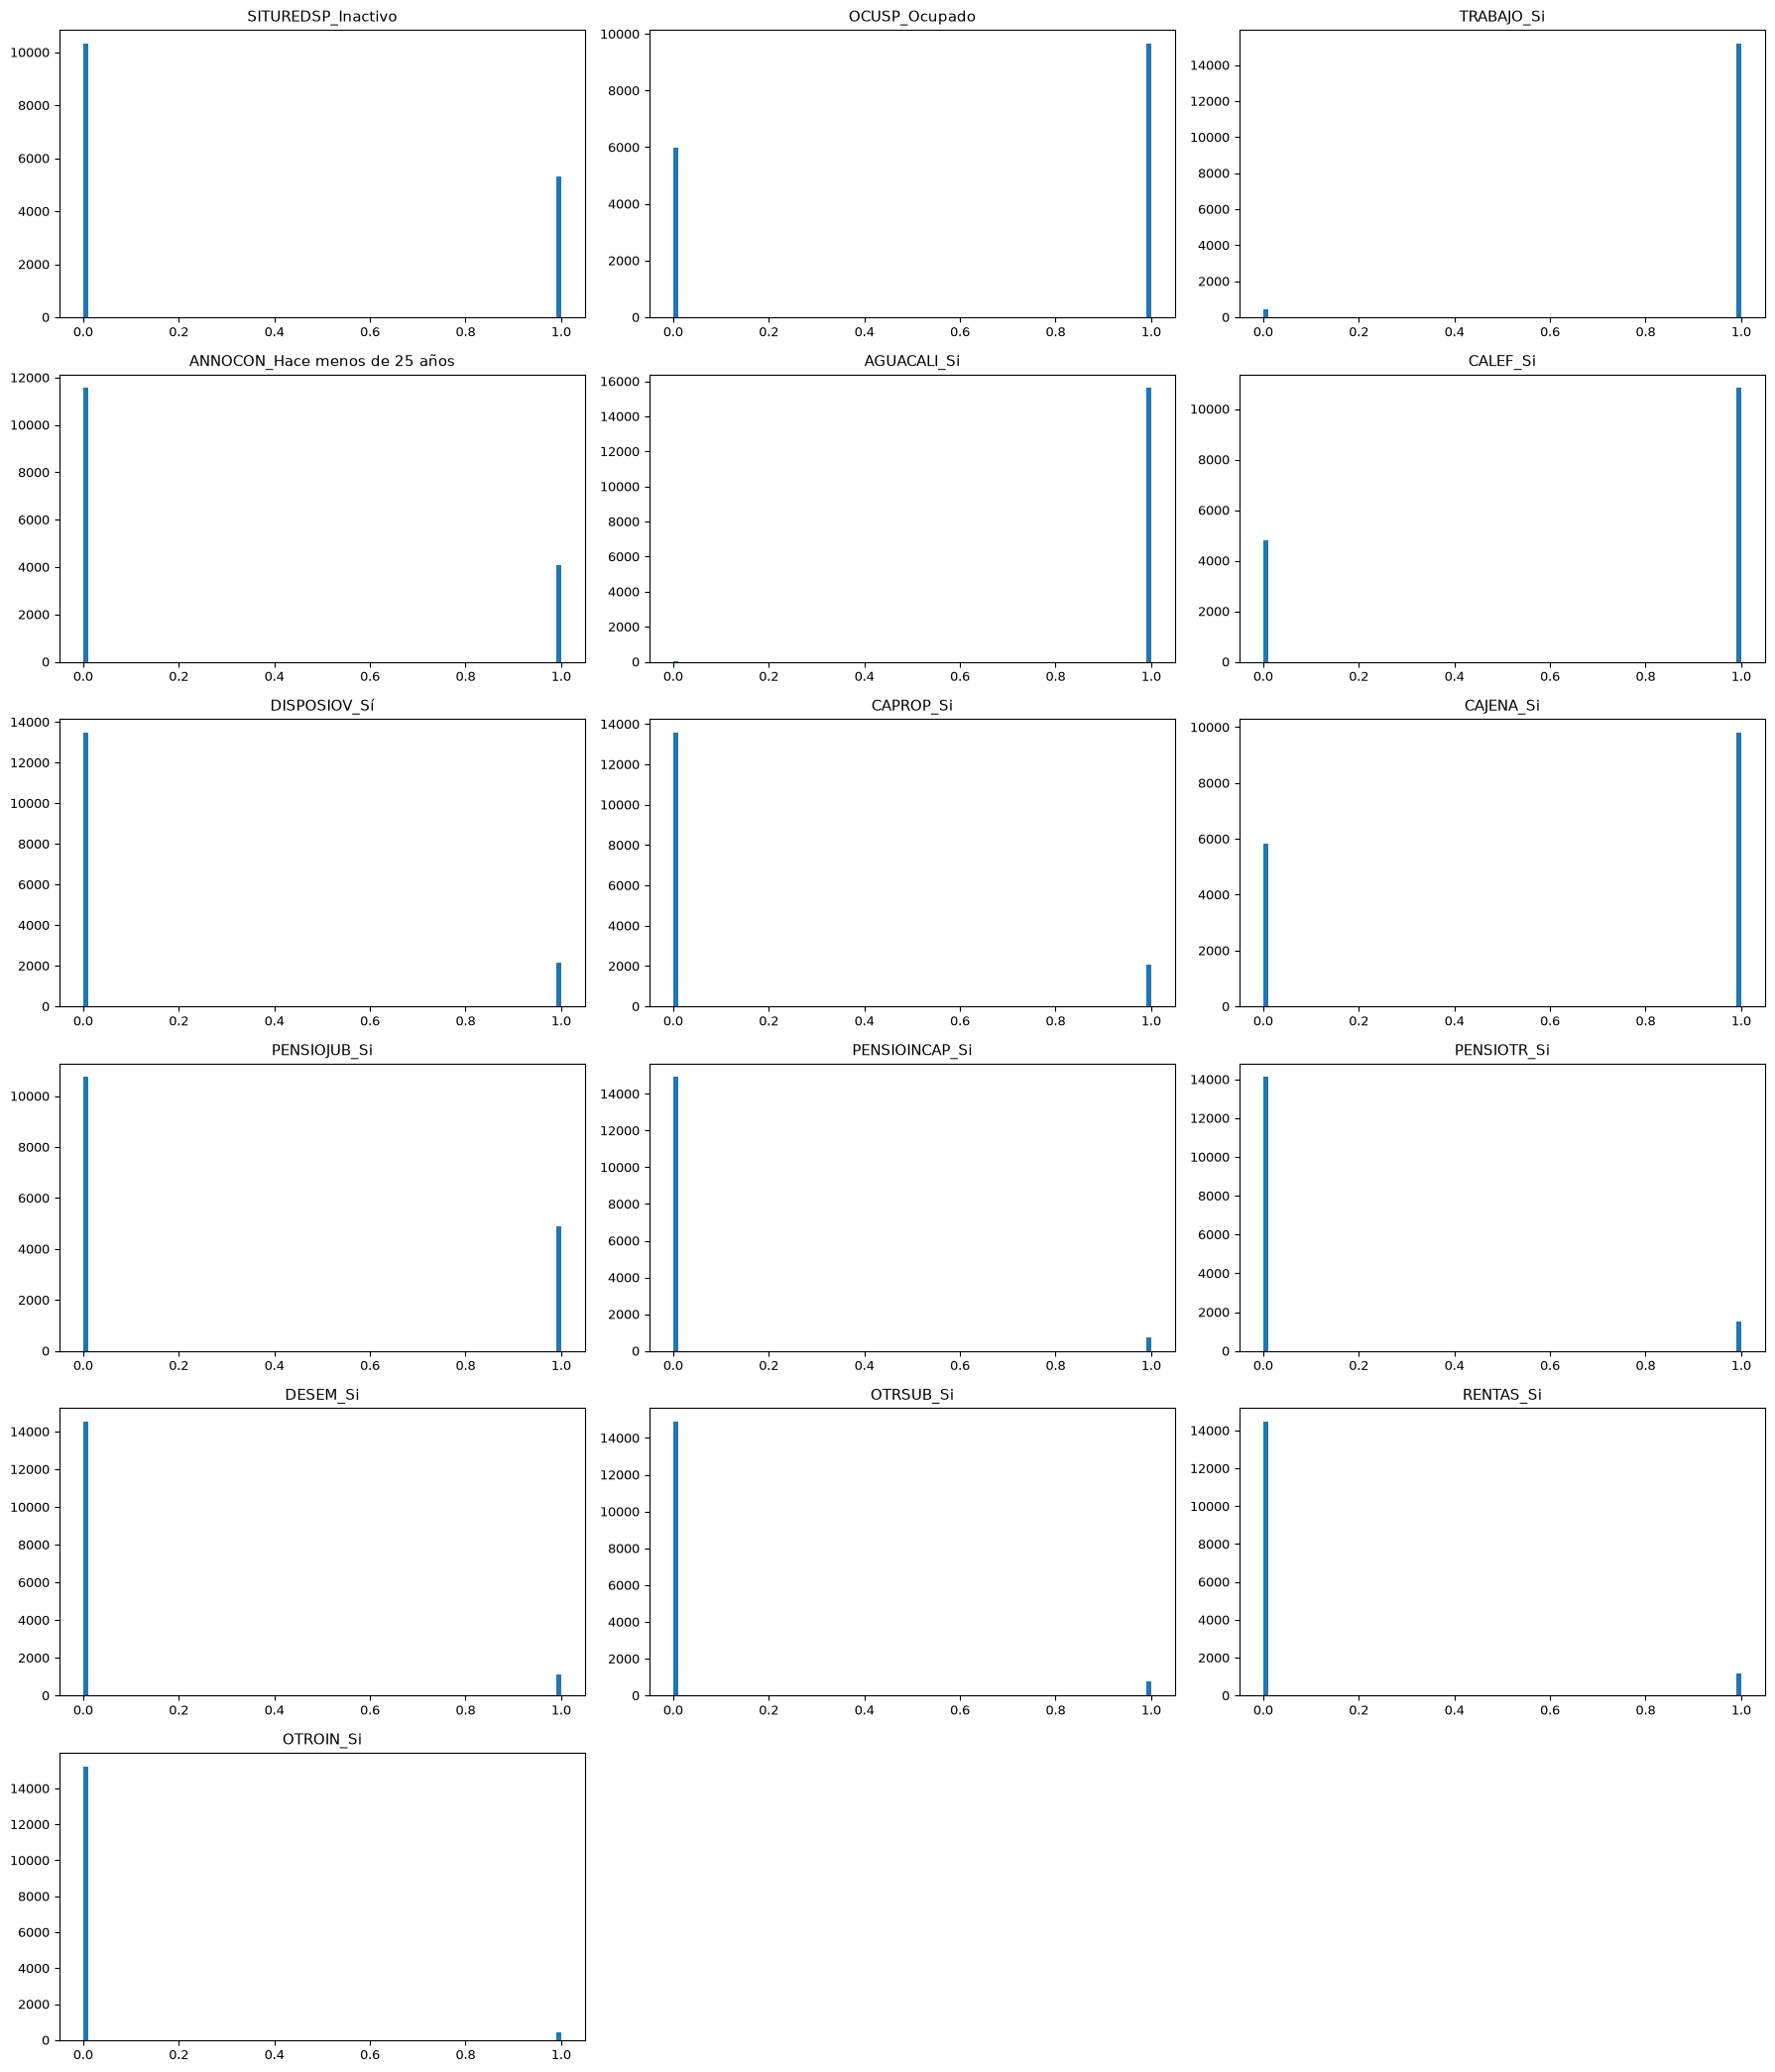

In [67]:
num_cols = train_set_with_bin.select_dtypes(include="number").columns.tolist()
tam_bloque = 18

for inicio in range(0, len(num_cols), tam_bloque):
    bloque = num_cols[inicio : inicio + tam_bloque]
    n_cols = 3
    n_rows = math.ceil(len(bloque) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3.5))
    axes = axes.ravel()

    for i, col in enumerate(bloque):
        axes[i].hist(train_set_with_bin[col].dropna(), bins=100)
        axes[i].set_title(col, fontsize=11)
        axes[i].tick_params(axis="both", labelsize=9)

    for j in range(len(bloque), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

In [68]:
# df_correlaciones = pd.DataFrame({"pearson": train_set_with_bin[num_cols].corr(method= "pearson")[target], "spearman" : train_set_with_bin[num_cols].corr(method= "spearman")[target]})
# df_correlaciones

In [69]:
resultados = []

for col in num_cols:
    if col == target:
        resultados.append({
            "variable": col,
            "pearson": 1.0,
            "p_pearson": 0.0,
            "spearman": 1.0,
            "p_spearman": 0.0
        })
        continue

    # Filtramos pares sin NaN para evitar errores en scipy.stats
    sub = train_set_with_bin[[col, target]].dropna()

    if len(sub) > 2 and sub[col].nunique() > 1:
        r_p, p_p = stats.pearsonr(sub[col], sub[target])
        r_s, p_s = stats.spearmanr(sub[col], sub[target])
    else:
        r_p, p_p, r_s, p_s = np.nan, np.nan, np.nan, np.nan

    resultados.append({
        "variable": col,
        "pearson": r_p,
        "p_pearson": p_p,
        "spearman": r_s,
        "p_spearman": p_s
    })

df_correlaciones = (
    pd.DataFrame(resultados)
    .set_index("variable")
)

df_correlaciones.round(4)

,pearson,p_pearson,spearman,p_spearman
variable,,,,
GASTO_SUMINISTROS,1.0000,0.0000,1.0000,0.0000
NMIEMB,0.2417,0.0000,0.2919,0.0000
NMIEM1,0.2566,0.0000,0.3011,0.0000
NMIEM2,0.0583,0.0000,0.0868,0.0000
NMIEM3,0.0699,0.0000,0.1007,0.0000
NMIEM4,0.2562,0.0000,0.2993,0.0000
NMIEM5,0.0836,0.0000,0.1160,0.0000
NMIEM6,0.2558,0.0000,0.2971,0.0000
NMIEM7,0.0213,0.0076,0.0307,0.0001


In [70]:
train_set_with_bin[num_cols].corr(method= "pearson").iloc[1:23, 1:23]

,NMIEMB,NMIEM1,NMIEM2,NMIEM3,NMIEM4,NMIEM5,NMIEM6,NMIEM7,NMIEM8,NMIEM9,...,NMIEM12,NMIEM13,NUMACTI,NUMINACTI,NUMOCUP,NUMNOCUP,NUMESTU,NUMNOESTU,NNINOSD,NHIJOSD
NMIEMB,1.000000,0.837227,0.576606,0.626081,0.802091,0.679254,0.767553,0.315473,0.566971,0.480210,...,-0.156351,-0.058224,0.625837,0.633650,0.566058,0.671965,0.429538,0.908811,0.767346,0.763659
NMIEM1,0.837227,1.000000,0.035957,0.136964,0.968088,0.241939,0.927998,-0.002656,0.161094,0.637021,...,-0.024016,-0.005661,0.587947,0.467049,0.521628,0.519728,0.571456,0.663014,0.433181,0.428985
NMIEM2,0.576606,0.035957,1.000000,0.939506,0.019425,0.879840,0.016205,0.580482,0.795433,-0.074172,...,-0.249843,-0.097945,0.265274,0.460177,0.255114,0.451493,-0.068816,0.670244,0.755101,0.754633
NMIEM3,0.626081,0.136964,0.939506,1.000000,0.036500,0.946051,0.025703,0.520135,0.897185,-0.042562,...,-0.275680,-0.106573,0.285944,0.501737,0.278352,0.489022,-0.037464,0.710541,0.824525,0.824108
NMIEM4,0.802091,0.968088,0.019425,0.036500,1.000000,0.145965,0.964007,0.005947,0.039490,0.648032,...,0.010760,0.007003,0.583071,0.427811,0.512272,0.486655,0.579186,0.620537,0.351937,0.347532
NMIEM5,0.679254,0.241939,0.879840,0.946051,0.145965,1.000000,0.050942,0.471894,0.859219,0.135333,...,-0.298543,-0.113110,0.312604,0.541994,0.301600,0.530907,0.151020,0.682337,0.890319,0.889369
NMIEM6,0.767553,0.927998,0.016205,0.025703,0.964007,0.050942,1.000000,0.017151,0.021105,0.535274,...,0.047982,0.019558,0.578619,0.388903,0.506882,0.450726,0.452618,0.640770,0.266613,0.262425
NMIEM7,0.315473,-0.002656,0.580482,0.520135,0.005947,0.471894,0.017151,1.000000,0.089446,-0.074582,...,-0.144378,-0.056578,0.165852,0.231227,0.151486,0.236324,-0.081056,0.386758,0.394653,0.391619
NMIEM8,0.566971,0.161094,0.795433,0.897185,0.039490,0.859219,0.021105,0.089446,1.000000,-0.011067,...,-0.246825,-0.095023,0.247691,0.465532,0.246266,0.448068,-0.001774,0.628602,0.757442,0.758525
NMIEM9,0.480210,0.637021,-0.074172,-0.042562,0.648032,0.135333,0.535274,-0.074582,-0.011067,1.000000,...,-0.228222,-0.073683,0.357210,0.248068,0.305552,0.292386,0.827823,0.149262,0.458750,0.451586


In [71]:
train_set_with_bin[num_cols].corr(method= "spearman").iloc[1:23, 1:23]

,NMIEMB,NMIEM1,NMIEM2,NMIEM3,NMIEM4,NMIEM5,NMIEM6,NMIEM7,NMIEM8,NMIEM9,...,NMIEM12,NMIEM13,NUMACTI,NUMINACTI,NUMOCUP,NUMNOCUP,NUMESTU,NUMNOESTU,NNINOSD,NHIJOSD
NMIEMB,1.000000,0.859966,0.549602,0.597101,0.830011,0.649422,0.800061,0.305527,0.543270,0.460812,...,-0.196587,-0.069729,0.645101,0.584035,0.585166,0.624810,0.419137,0.916972,0.738201,0.734915
NMIEM1,0.859966,1.000000,0.087353,0.182840,0.970248,0.274914,0.936429,0.017661,0.195234,0.573353,...,-0.049012,-0.020434,0.575055,0.453099,0.511132,0.506917,0.519326,0.735027,0.435309,0.431535
NMIEM2,0.549602,0.087353,1.000000,0.922801,0.063025,0.857949,0.051062,0.561616,0.787482,-0.046153,...,-0.288032,-0.109033,0.324661,0.400556,0.305821,0.393001,-0.039228,0.610272,0.737898,0.737115
NMIEM3,0.597101,0.182840,0.922801,1.000000,0.089913,0.932042,0.067364,0.509414,0.897296,0.008363,...,-0.319343,-0.118768,0.350779,0.434486,0.334688,0.423789,0.012967,0.649713,0.807237,0.806339
NMIEM4,0.830011,0.970248,0.063025,0.089913,1.000000,0.189959,0.968473,0.027432,0.087239,0.580809,...,-0.012845,-0.009078,0.563526,0.422991,0.495934,0.481193,0.524728,0.700286,0.364221,0.360325
NMIEM5,0.649422,0.274914,0.857949,0.932042,0.189959,1.000000,0.103795,0.466620,0.841751,0.177908,...,-0.344670,-0.125901,0.381517,0.471124,0.363963,0.461733,0.195621,0.621159,0.874897,0.873371
NMIEM6,0.800061,0.936429,0.051062,0.067364,0.968473,0.103795,1.000000,0.039422,0.057116,0.476966,...,0.022175,0.002342,0.552803,0.393009,0.483963,0.453767,0.408941,0.712838,0.292582,0.288845
NMIEM7,0.305527,0.017661,0.561616,0.509414,0.027432,0.466620,0.039422,1.000000,0.145239,-0.079298,...,-0.161332,-0.061016,0.194313,0.204793,0.172981,0.206530,-0.085919,0.354824,0.395250,0.392746
NMIEM8,0.543270,0.195234,0.787482,0.897296,0.087239,0.841751,0.057116,0.145239,1.000000,0.043548,...,-0.283797,-0.105236,0.300243,0.417726,0.291656,0.403164,0.050789,0.577845,0.736716,0.737055
NMIEM9,0.460812,0.573353,-0.046153,0.008363,0.580809,0.177908,0.476966,-0.079298,0.043548,1.000000,...,-0.254895,-0.080815,0.353856,0.205207,0.310265,0.243712,0.810291,0.174114,0.476348,0.468607


In [72]:
def evaluar_binarias_mw(df: pd.DataFrame, cols_bin: list[str], target: str = "GASTO_SUMINISTROS") -> pd.DataFrame:
    filas = []
    for col in cols_bin:
        sub = df[[col, target]].dropna()
        vals = sub[col].unique()
        if len(vals) != 2:
            continue
        g0 = sub.loc[sub[col] == vals[0], target]
        g1 = sub.loc[sub[col] == vals[1], target]
        _, p_val = mannwhitneyu(g0, g1, alternative="two-sided")
        filas.append({
            "col": col,
            "n_g0": len(g0),
            "n_g1": len(g1),
            "mediana_g0": g0.median(),
            "mediana_g1": g1.median(),
            "diff_mediana": abs(g1.median() - g0.median()),
            "p_valor": p_val,
        })
    return pd.DataFrame(filas).sort_values("p_valor")

evaluar_binarias_mw(train_set_with_bin, cols_bin_out).round(4)

,col,n_g0,n_g1,mediana_g0,mediana_g1,diff_mediana,p_valor
8,CALEF_Si,10831,4804,1330.8712,1006.7363,324.1349,0.0000
10,CAPROP_Si,13579,2056,1197.9344,1380.2304,182.2960,0.0000
1,SEXOSP_Mujer,9811,5824,1265.1831,1151.4250,113.7581,0.0000
11,CAJENA_Si,5827,9808,1155.8037,1260.0000,104.1963,0.0000
4,OCUSP_Ocupado,5971,9664,1158.3234,1258.6156,100.2922,0.0000
0,CAPROV_Sí,10513,5122,1253.1233,1162.8456,90.2777,0.0000
5,TRABAJO_Si,15204,431,1226.3076,984.9252,241.3824,0.0000
16,OTRSUB_Si,14885,750,1226.8613,1079.6643,147.1970,0.0000
12,PENSIOJUB_Si,4891,10744,1255.8085,1200.0000,55.8085,0.0000
17,RENTAS_Si,14466,1169,1210.0510,1332.2266,122.1756,0.0000


In [ ]:
cols_excluidas = [
    # Bloque del hogar: duplicadas, redundantes o con señal muy débil/nula frente a GASTO_SUMINISTROS
    "NHIJOSD", "NUMESTU", "NUMNOESTU", "NUMACTI", "NUMINACTI",
    "NMIEM1", "NMIEM6", "NMIEMSD", "NMIEMHU", "NMIEMIN",
    "NMIEM2", "NMIEM3", "NMIEM5", "NMIEM7", "NMIEM8",
    "NMIEM11", "NMIEM12", "NMIEM13", "CALEF", "OCUSP"
    # Binarias muy desbalanceadas con correlación mínima y poca diferencia entre ellas frente a GASTO_SUMINISTROS
    "SITURESSP_Presente", "PENSIOINCAP_Si", "OTROIN_Si", "SITURESSP", "PENSIOINCAP", "OTROIN"
]

In [74]:
no_num_multi =  [col for col in no_num if col not in no_num_binary]
no_num_multi

['CCAA',
 'NUTS1',
 'TAMAMU',
 'DENSIDAD',
 'TIPHOGAR1',
 'TIPHOGAR7',
 'TIPHOGAR8',
 'PAISNACSP',
 'NACIONASP',
 'ESTADOCIVILSP',
 'PAISPADRESP',
 'PAISMADRESP',
 'ESTUDIOSSP',
 'ESTUDREDSP',
 'SITUACTSP',
 'JORNADASP',
 'PERCEPSP',
 'OCUPA',
 'OCUPARED',
 'ACTESTB',
 'ACTESTBRED',
 'SITPROF',
 'SECTOR',
 'CONTRATO',
 'TIPOCONT',
 'SITSOCI',
 'SITSOCIRE',
 'REGTEN',
 'TIPOEDIF',
 'ZONARES',
 'TIPOCASA',
 'FUENAGUA',
 'FUENCALE',
 'FUENPRIN',
 'FUENPRINRED']

In [85]:
for col in no_num_multi:

    resumen = (
        train_set.groupby(col)["GASTO_SUMINISTROS"]
        .agg(["count", "mean", "median", "std"])
        .sort_values("mean", ascending=False)
    )

    print(f"\n--- {col} ---")
    print(resumen)


--- CCAA ---
                             count         mean       median         std
CCAA                                                                    
Castilla-La Mancha             870  1705.421147  1522.817432  942.936509
Cataluña                      1180  1594.922699  1392.640667  870.312487
Madrid, Comunidad de          1384  1567.929879  1398.489640  782.410302
Balears, Illes                 386  1561.417278  1445.817535  712.198778
Castilla y León               1097  1556.607064  1360.559987  899.728101
Navarra, Comunidad Foral de    461  1554.131060  1320.000008  889.641300
Rioja, La                      433  1469.135500  1296.410407  775.144480
Aragón                         762  1446.939438  1233.290003  895.640410
Galicia                       1040  1425.645659  1212.804908  845.729079
Asturias, Principado de        606  1397.504414  1262.500800  672.240380
Murcia, Región de              732  1384.463451  1245.637205  729.262460
Cantabria                      538  1

In [87]:
from scipy.stats import f_oneway, kruskal

resultados = []

for col in no_num_multi:

    grupos = [
        grupo["GASTO_SUMINISTROS"].dropna().values
        for _, grupo in train_set.groupby(col)
        if len(grupo["GASTO_SUMINISTROS"].dropna()) >= 2
    ]

    if len(grupos) >= 2:

        anova = f_oneway(*grupos)
        kruskal_test = kruskal(*grupos)

        resultados.append({
            "variable": col,
            "p_anova": anova.pvalue,
            "p_kruskal": kruskal_test.pvalue
        })

resultados_cat = pd.DataFrame(resultados)

print(
    resultados_cat.sort_values("p_kruskal")
)

         variable        p_anova      p_kruskal
5       TIPHOGAR7  2.264368e-236   0.000000e+00
4       TIPHOGAR1  9.293793e-252   0.000000e+00
31       FUENAGUA  1.232423e-278  2.738132e-278
9   ESTADOCIVILSP  1.916417e-160  2.172228e-206
0            CCAA  2.815728e-165  9.142453e-191
6       TIPHOGAR8  1.115053e-135  7.510418e-171
1           NUTS1   1.429015e-95  2.575977e-120
32       FUENCALE  7.140087e-129  7.625577e-115
30       TIPOCASA  4.389970e-153  1.867238e-104
28       TIPOEDIF  3.968081e-152   3.532139e-85
33       FUENPRIN   3.453700e-69   1.989233e-80
14      SITUACTSP   1.279059e-47   6.651491e-70
26      SITSOCIRE   6.092293e-58   1.318196e-67
25        SITSOCI   5.295962e-56   1.986420e-66
18       OCUPARED   3.661664e-45   8.115816e-50
17          OCUPA   1.940988e-46   1.784541e-48
24       TIPOCONT   5.719297e-32   4.828805e-47
2          TAMAMU   3.288373e-56   7.596919e-36
34    FUENPRINRED   1.018108e-35   4.907585e-34
3        DENSIDAD   6.896061e-54   2.715

In [88]:
from scipy.stats import f_oneway
import numpy as np

resultados = []

for col in no_num_multi:

    grupos = [
        grupo["GASTO_SUMINISTROS"].dropna().values
        for _, grupo in train_set.groupby(col)
        if len(grupo["GASTO_SUMINISTROS"].dropna()) >= 2
    ]

    if len(grupos) >= 2:

        valores = np.concatenate(grupos)
        media_global = valores.mean()

        ss_total = np.sum((valores - media_global) ** 2)

        ss_entre = sum(
            len(g) * (g.mean() - media_global) ** 2
            for g in grupos
        )

        eta2 = ss_entre / ss_total if ss_total > 0 else np.nan

        resultados.append({
            "variable": col,
            "eta2": eta2,
            "p_kruskal": kruskal(*grupos).pvalue
        })

resultados_cat = pd.DataFrame(resultados)

print(resultados_cat.sort_values("eta2", ascending=False))

         variable      eta2      p_kruskal
31       FUENAGUA  0.079807  2.738132e-278
4       TIPHOGAR1  0.074255   0.000000e+00
5       TIPHOGAR7  0.068819   0.000000e+00
32       FUENCALE  0.054499  7.625577e-115
0            CCAA  0.051927  9.142453e-191
9   ESTADOCIVILSP  0.046689  2.172228e-206
28       TIPOEDIF  0.043998   3.532139e-85
30       TIPOCASA  0.043892  1.867238e-104
6       TIPHOGAR8  0.039347  7.510418e-171
1           NUTS1  0.028824  2.575977e-120
33       FUENPRIN  0.021768   1.989233e-80
25        SITSOCI  0.019002   1.986420e-66
26      SITSOCIRE  0.018378   1.318196e-67
2          TAMAMU  0.016829   7.596919e-36
17          OCUPA  0.015613   1.784541e-48
3        DENSIDAD  0.015539   2.715470e-30
14      SITUACTSP  0.014837   6.651491e-70
18       OCUPARED  0.013980   8.115816e-50
24       TIPOCONT  0.010928   4.828805e-47
21        SITPROF  0.010835   7.935771e-26
29        ZONARES  0.010514   4.221894e-25
34    FUENPRINRED  0.010297   4.907585e-34
19        A

In [75]:
grupos_cat = {
    "grupo_a_suministros_estructural": ["FUENCALE", "FUENAGUA"],
    "grupo_b_empleo_estatus_multiclase": [
        "OCUPA", "OCUPARED", "ACTESTB", "ACTESTBRED",
        "SITPROF", "SITSOCI", "SITSOCIRE"
    ],
    "grupo_c_ingresos_principales": ["FUENPRIN", "FUENPRINRED"],
    "grupo_d_territorio": ["CCAA", "NUTS1", "CAPROV", "TAMAMU", "DENSIDAD", "ZONARES"],
    "grupo_e_tipologia_hogar": ["TIPHOGAR1", "TIPHOGAR7", "TIPHOGAR8"],
    "grupo_f_demografia_sp": [
        "SEXOSP", "PAISNACSP", "NACIONASP", "ESTADOCIVILSP",
        "PAISPADRESP", "PAISMADRESP", "ESTUDIOSSP",
        "ESTUDREDSP", "SITUACTSP", "SITUREDSP", "PERCEPSP"
    ],
    "grupo_g_vivienda_cat": [
        "REGTEN", "TIPOEDIF", "TIPOCASA", "ANNOCON", "AGUACALI", "DISPOSIOV"
    ],
    "grupo_h_binarias_laborales_estructurales": [
        "JORNADASP", "SECTOR", "CONTRATO", "TIPOCONT", "TRABAJO"
    ],
    "grupo_i_ingresos_y_tenencia_bin": [
        "CAPROP", "CAJENA", "PENSIOTR", "DESEM", "OTRSUB", "RENTAS", "PENSIOJUB"
    ],
}

In [76]:
no_aplica_cols = (
    grupos_cat["grupo_a_suministros_estructural"]
    + grupos_cat["grupo_h_binarias_laborales_estructurales"]
)
no_consta_cols = grupos_cat["grupo_b_empleo_estatus_multiclase"]
moda_cat_cols = (
    grupos_cat["grupo_c_ingresos_principales"]
    + grupos_cat["grupo_d_territorio"]
    + grupos_cat["grupo_e_tipologia_hogar"]
    + grupos_cat["grupo_f_demografia_sp"]
    + grupos_cat["grupo_g_vivienda_cat"]
    + grupos_cat["grupo_i_ingresos_y_tenencia_bin"]
)

# Ajusta estas dos listas a tus columnas numéricas finales (sin la target ni excluidas)
num_con_nulos = ["VALOREST", "NHABIT"]

num_sin_nulos = [
    "NMIEMB", "NMIEM4", "NMIEM9", "NMIEM10",
    "NUMOCUP", "NUMNOCUP", "NNINOSD",
    "UC1", "UC2", "PF2TEO", "PF2RECO",
    "EDADSP", "SUPERF", "IMPEXAC", "NUMPERI",
]

no_aplica_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="No_aplica")),
    ("ohe", OneHotEncoder(handle_unknown="ignore")),
])

no_consta_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="No_consta")),
    ("ohe", OneHotEncoder(handle_unknown="ignore")),
])

moda_cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore")),
])

num_nulos_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

num_limpias_pipe = Pipeline([
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("cat_no_aplica", no_aplica_pipe, no_aplica_cols),
        ("cat_no_consta", no_consta_pipe, no_consta_cols),
        ("cat_moda", moda_cat_pipe, moda_cat_cols),
        ("num_nulos", num_nulos_pipe, num_con_nulos),
        ("num_limpias", num_limpias_pipe, num_sin_nulos),
    ],
    remainder="drop",  # evita que se cuele cualquier columna no listada
)

modelo = Pipeline([
    ("prep", preprocessor),
    ("reg", Ridge(alpha=1.0)),
])

scores = cross_validate(
    modelo,
    X_train,
    y_train,
    cv=5,
    scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"},
    n_jobs=-1,
)

In [77]:
todas_las_listas = (
    list(cols_bin_out)
    + no_aplica_cols
    + no_consta_cols
    + moda_cat_cols
    + num_con_nulos
    + num_sin_nulos
)

todas_en_grupos = set(todas_las_listas)

columnas_base = set(df_gasto_energetico.columns) - {target} - set(cols_excluidas)

sin_asignar = sorted(columnas_base - todas_en_grupos)
duplicadas = len(todas_las_listas) - len(todas_en_grupos)
lista_duplicadas = sorted({c for c in todas_las_listas if todas_las_listas.count(c) > 1})

print("Columnas sin asignar:", sin_asignar)
print("Columnas duplicadas entre listas:", duplicadas)
if lista_duplicadas:
    print("Nombres duplicados:", lista_duplicadas)

Columnas sin asignar: ['OCUSP']
Columnas duplicadas entre listas: 0


In [83]:
X_train_prep = preprocessor.fit_transform(X_train)

# Si la salida es sparse (frecuente con OneHotEncoder), conviértela o usa .data
arr = X_train_prep.toarray() if hasattr(X_train_prep, "toarray") else X_train_prep

print("Shape transformado:", arr.shape)
print("Total de NaN tras preprocesar:", np.isnan(arr).sum())
print("Total de inf/-inf tras preprocesar:", np.isinf(arr).sum())

Shape transformado: (15635, 274)
Total de NaN tras preprocesar: 0
Total de inf/-inf tras preprocesar: 0
